In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv('preprocessed_TRAIN.csv')
df.head(10)


,Unnamed: 0,built_area,modul_price,typology,weeks_delay,weeks_duration
0,0,16971.669353,800.717684,COLLECTIVE,0,69
1,1,12434.613919,680.061254,COMMERCIAL,2,92
2,2,11003.411065,1190.379098,COLLECTIVE,1,45
3,3,10423.124959,987.449779,OTHERS,4,35
4,4,22990.708329,564.466572,COMMERCIAL,6,85
5,5,11535.690794,597.376142,COLLECTIVE,17,30
6,6,9803.039984,528.265243,COLLECTIVE,22,75
7,7,124.870015,776.731080,DETACHED,4,36
8,8,4275.241203,595.600384,COMMERCIAL,24,34
9,9,7341.823010,841.311312,COLLECTIVE,22,63


In [2]:
df.isnull().sum()

Unnamed: 0        0
built_area        0
modul_price       0
typology          0
weeks_delay       0
weeks_duration    0
dtype: int64

In [3]:
df.shape


(3555, 6)

In [4]:
df_new = df.drop(df.columns[0], axis=1)

In [5]:
df_new.columns

Index(['built_area', 'modul_price', 'typology', 'weeks_delay',
       'weeks_duration'],
      dtype='str')

In [6]:
df_new=df.drop(df.columns[0],axis=1)
df_new


,built_area,modul_price,typology,weeks_delay,weeks_duration
0,16971.669353,800.717684,COLLECTIVE,0,69
1,12434.613919,680.061254,COMMERCIAL,2,92
2,11003.411065,1190.379098,COLLECTIVE,1,45
3,10423.124959,987.449779,OTHERS,4,35
4,22990.708329,564.466572,COMMERCIAL,6,85
...,...,...,...,...,...
3550,4865.725064,959.812830,COLLECTIVE,4,59
3551,8399.002755,485.539058,COLLECTIVE,11,61
3552,10564.526848,405.535002,COLLECTIVE,44,70
3553,5694.837811,617.497125,COMMERCIAL,7,88


In [39]:
df_new.describe().T

,count,mean,std,min,25%,50%,75%,max
built_area,3555.0,8573.883884,5835.105470,50.763235,3906.039796,8257.005747,12672.535958,32385.786541
modul_price,3555.0,737.783916,251.400824,182.092514,565.767107,700.774198,879.700703,1903.912429
weeks_delay,3555.0,17.795218,16.501862,0.000000,5.000000,13.000000,26.000000,113.000000
weeks_duration,3555.0,54.639944,19.988243,13.000000,39.000000,52.000000,70.000000,122.000000
DELAYED,3555.0,0.654852,0.475483,0.000000,0.000000,1.000000,1.000000,1.000000


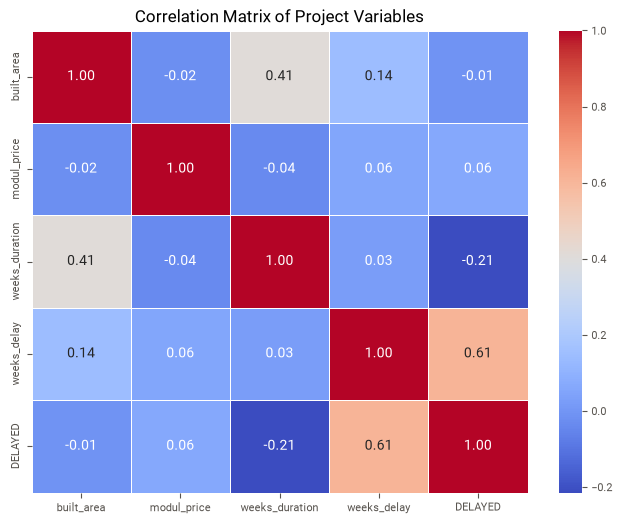

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



df['DELAYED'] = (df['weeks_delay'] > 0.15 * df['weeks_duration']).astype(int)

numeric_columns = ['built_area', 'modul_price', 'weeks_duration', 'weeks_delay', 'DELAYED']

plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_columns].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Project Variables')
plt.show()

In [10]:
df = pd.get_dummies(df, columns=['typology'], drop_first=True)

print(df.head())

   Unnamed: 0    built_area  modul_price  weeks_delay  weeks_duration  \
0           0  16971.669353   800.717684            0              69   
1           1  12434.613919   680.061254            2              92   
2           2  11003.411065  1190.379098            1              45   
3           3  10423.124959   987.449779            4              35   
4           4  22990.708329   564.466572            6              85   

   DELAYED  typology_COMMERCIAL  typology_DETACHED  typology_OTHERS  
0        0                False              False            False  
1        0                 True              False            False  
2        0                False              False            False  
3        0                False              False             True  
4        0                 True              False            False  


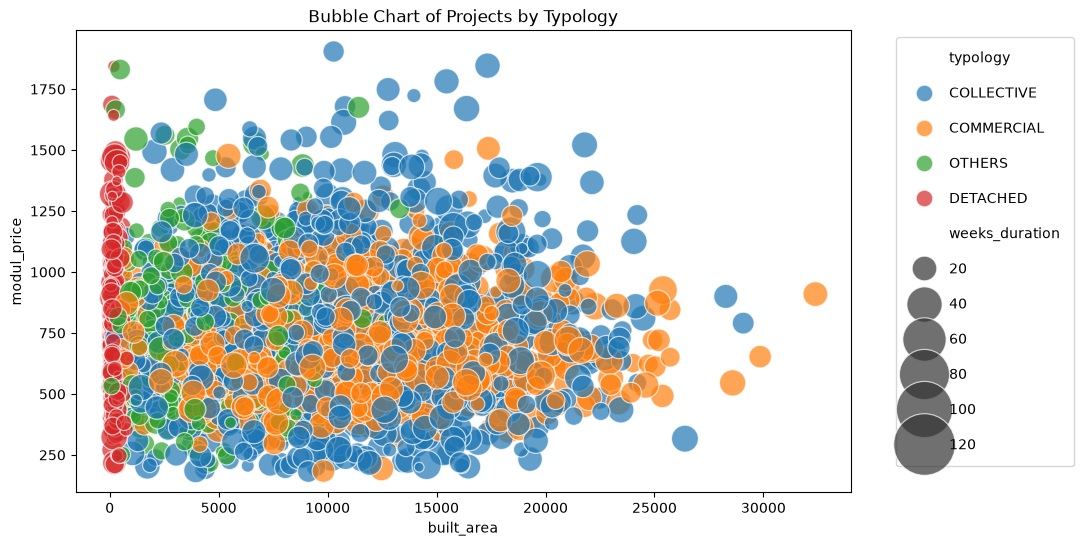

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_plot, x='built_area', y='modul_price', 
                size='weeks_duration', hue='typology', 
                sizes=(50, 500), alpha=0.7)

plt.title('Bubble Chart of Projects by Typology')

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', 
           markerscale=2, labelspacing=1.5, borderpad=1)

plt.show()